# SafeStep · 4 — Deep learning on raw signals (multi-task: fall + activity)
`7 phone-ready signals × 3 s` → `1D-CNN · CNN-BiLSTM · Hybrid (CNN + 120 features)` → `same validation tuning` → `same streaming test`

**Runtime → Change runtime type → T4 GPU.** Checkpoints are saved to Drive after every epoch; a disconnect resumes training.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as Fnn
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, balanced_accuracy_score, confusion_matrix, classification_report
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

BASE = '/content/drive/MyDrive/Daffodil Robo Tech Olympiad'
PROJ = f'{BASE}/SafeStep'
D = {k: f'{PROJ}/{k}' for k in ['data', 'artifacts', 'figures', 'models', 'code']}
DEEP = f"{D['models']}/deep"; os.makedirs(DEEP, exist_ok=True)
sys.path.insert(0, D['code']); import safestep_core as core
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); rng = np.random.default_rng(SEED)
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save_fig(name): plt.savefig(f"{D['figures']}/{name}.png", dpi=300, bbox_inches='tight')
print('device:', DEV, torch.cuda.get_device_name(0) if DEV == 'cuda' else '(slow — switch to GPU)')

F    = pd.read_parquet(f"{D['data']}/features_345.parquet").set_index('win_id')
wm   = pd.read_parquet(f"{D['data']}/windows_meta.parquet").set_index('win_id')
meta = pd.read_parquet(f"{D['data']}/trials_meta.parquet").set_index('trial_id')
SEL  = json.load(open(f"{D['artifacts']}/feature_selection.json"))
FS, W = core.FS, core.WIN
PHONE = SEL['selected_phone']
CH = core.INVARIANT_SIGNALS                     # svm, dyn, vert, horiz, gyro, jerk, tilt
print(F.shape, len(PHONE), CH)

device: cpu (slow — switch to GPU)
(136051, 345) 120 ['svm', 'dyn', 'vert', 'horiz', 'gyro', 'jerk', 'tilt']


## 1 · Raw window tensor (cached in Drive)

In [3]:
RAW_PATH = f"{D['data']}/raw_windows_7ch.npy"
if os.path.exists(RAW_PATH):
    XR = np.load(RAW_PATH, mmap_mode='r')
else:
    signals = np.load(f"{D['data']}/signals_50hz.npz")['signals']
    XR = np.zeros((len(wm), len(CH), W), np.float16)
    pos = 0
    for tid, g in tqdm(wm.groupby('trial_id', sort=True), desc='raw windows'):
        r = meta.loc[tid]
        x = signals[r.offset:r.offset + r.n_samples]
        S = core.trial_windows(x[:, 0:3], x[:, 3:6], g.start.values)
        XR[wm.index.get_indexer(g.index)] = np.stack([S[c] for c in CH], axis=1).astype(np.float16)
    np.save(RAW_PATH, XR)
XR = np.asarray(XR, dtype=np.float32)
print('raw tensor:', XR.shape, f'{XR.nbytes/1e9:.2f} GB')

raw windows:   0%|          | 0/4505 [00:00<?, ?it/s]

raw tensor: (136051, 7, 150) 0.57 GB


## 2 · Labels, masks, normalisation (train statistics only)

In [4]:
t_end = wm.t_end_rel_impact.values
wm['y_fall_train'] = np.select(
    [wm.phase == 'impact', wm.phase == 'adl',
     (wm.phase == 'pre_fall') & (t_end < -1.0), (wm.phase == 'post_fall') & (t_end > W / FS + 1.0)],
    [1, 0, 0, 0], -1)
ACT_ENC = LabelEncoder().fit(sorted(wm.y_activity[wm.y_activity != 'ignore'].unique()))
ACT_CLASSES = list(ACT_ENC.classes_); NA = len(ACT_CLASSES)
y_fall = wm.y_fall_train.values.astype(np.int64)
y_act = np.full(len(wm), -1, np.int64)
ma = (wm.y_activity != 'ignore').values
y_act[ma] = ACT_ENC.transform(wm.y_activity.values[ma])

split = wm.split.values
useful = (y_fall >= 0) | (y_act >= 0)
IDX = {s: np.where((split == s) & useful)[0] for s in ['train', 'val', 'test']}

tr = IDX['train']
mu = XR[tr].mean(axis=(0, 2), keepdims=True); sd = XR[tr].std(axis=(0, 2), keepdims=True) + 1e-6
XR = (XR - mu) / sd
XF = F[PHONE].values.astype(np.float32)
fmu, fsd = XF[tr].mean(0), XF[tr].std(0) + 1e-6
XF = (XF - fmu) / fsd
json.dump({'channels': CH, 'raw_mean': mu.ravel().tolist(), 'raw_std': sd.ravel().tolist(),
           'feat_names': PHONE, 'feat_mean': fmu.tolist(), 'feat_std': fsd.tolist(), 'activity_classes': ACT_CLASSES},
          open(f'{DEEP}/normalisation.json', 'w'), indent=2)

pos_w = (y_fall[tr] == 0).sum() / max((y_fall[tr] == 1).sum(), 1)
cnt = np.bincount(y_act[tr][y_act[tr] >= 0], minlength=NA)
act_w = torch.tensor(cnt.sum() / (NA * np.maximum(cnt, 1)), dtype=torch.float32, device=DEV)
print({s: len(v) for s, v in IDX.items()}, f'| fall pos_weight={pos_w:.1f}')

{'train': 72070, 'val': 23464, 'test': 33342} | fall pos_weight=15.7


## 3 · Architectures

In [5]:
class ConvBlock(nn.Module):
    def __init__(self, cin, cout, k, pool=True, drop=0.1):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.GELU(),
                                  nn.Conv1d(cout, cout, k, padding=k // 2), nn.BatchNorm1d(cout))
        self.skip = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()
        self.post = nn.Sequential(nn.GELU(), nn.MaxPool1d(2) if pool else nn.Identity(), nn.Dropout(drop))
    def forward(self, x): return self.post(self.conv(x) + self.skip(x))

class Encoder(nn.Module):
    def __init__(self, cin):
        super().__init__()
        self.net = nn.Sequential(ConvBlock(cin, 64, 7), ConvBlock(64, 128, 5), ConvBlock(128, 128, 3, pool=False))
        self.out_dim = 256
    def forward(self, x):
        h = self.net(x)
        return torch.cat([h.mean(-1), h.amax(-1)], 1)

class LSTMEncoder(nn.Module):
    def __init__(self, cin):
        super().__init__()
        self.cnn = nn.Sequential(ConvBlock(cin, 64, 7), ConvBlock(64, 128, 5))
        self.lstm = nn.LSTM(128, 96, batch_first=True, bidirectional=True)
        self.out_dim = 384
    def forward(self, x):
        h, _ = self.lstm(self.cnn(x).transpose(1, 2))      # (B, T, 192)
        return torch.cat([h.mean(1), h.amax(1)], 1)

class MultiTask(nn.Module):
    def __init__(self, kind, cin=len(CH), nfeat=len(PHONE), na=NA):
        super().__init__()
        self.kind = kind
        self.enc = LSTMEncoder(cin) if kind == 'cnn_bilstm' else Encoder(cin)
        d = self.enc.out_dim
        if kind == 'hybrid':
            self.fenc = nn.Sequential(nn.Linear(nfeat, 128), nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(0.2), nn.Linear(128, 128), nn.GELU())
            d += 128
        self.trunk = nn.Sequential(nn.Linear(d, 128), nn.GELU(), nn.Dropout(0.3))
        self.fall_head = nn.Linear(128, 1)
        self.act_head = nn.Linear(128, na)
    def forward(self, xr, xf=None):
        h = self.enc(xr)
        if self.kind == 'hybrid': h = torch.cat([h, self.fenc(xf)], 1)
        h = self.trunk(h)
        return self.fall_head(h).squeeze(1), self.act_head(h)

for k in ['cnn', 'cnn_bilstm', 'hybrid']:
    m = MultiTask(k); print(f'{k:10s} {sum(p.numel() for p in m.parameters())/1e3:.0f}k parameters')

cnn        298k parameters
cnn_bilstm 389k parameters
hybrid     347k parameters


## 4 · Training (multi-task loss, light augmentation, early stopping on validation)

In [6]:
EPOCHS, BS, LR, PATIENCE = 30, 512, 2e-3, 6

def batches(idx, bs, shuffle):
    idx = rng.permutation(idx) if shuffle else idx
    for i in range(0, len(idx), bs): yield idx[i:i + bs]

def to_dev(b, aug=False):
    xr = torch.from_numpy(XR[b]).to(DEV); xf = torch.from_numpy(XF[b]).to(DEV)
    if aug:   # amplitude jitter + noise: mimics a different phone sensor
        xr = xr * (1 + 0.1 * torch.randn(xr.size(0), xr.size(1), 1, device=DEV)) + 0.05 * torch.randn_like(xr)
    return xr, xf

@torch.no_grad()
def predict(model, idx, bs=2048):
    model.eval(); pf, pa = [], []
    for b in batches(idx, bs, False):
        xr, xf = to_dev(b)
        lf, la = model(xr, xf)
        pf.append(torch.sigmoid(lf).float().cpu().numpy()); pa.append(torch.softmax(la, 1).float().cpu().numpy())
    return np.concatenate(pf), np.concatenate(pa)

def val_score(model):
    pf, pa = predict(model, IDX['val'])
    yf, ya = y_fall[IDX['val']], y_act[IDX['val']]
    ap = average_precision_score(yf[yf >= 0], pf[yf >= 0])
    f1 = f1_score(ya[ya >= 0], pa[ya >= 0].argmax(1), average='macro')
    return ap, f1

def train(kind):
    ck = f'{DEEP}/{kind}_checkpoint.pt'; best_path = f'{DEEP}/{kind}_best.pt'
    model = MultiTask(kind).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    steps = EPOCHS * int(np.ceil(len(IDX['train']) / BS))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps)
    hist, start, best, bad = [], 0, -1, 0
    if os.path.exists(ck):
        s = torch.load(ck, map_location=DEV, weights_only=False)
        model.load_state_dict(s['model']); opt.load_state_dict(s['opt']); sched.load_state_dict(s['sched'])
        hist, start, best, bad = s['hist'], s['epoch'] + 1, s['best'], s['bad']
        print(f'resumed {kind} at epoch {start}')
    pw = torch.tensor(pos_w, device=DEV)
    for ep in range(start, EPOCHS):
        if bad >= PATIENCE: break
        model.train(); t0, tl = time.time(), 0.0
        for b in batches(IDX['train'], BS, True):
            xr, xf = to_dev(b, aug=True)
            yf = torch.from_numpy(y_fall[b]).to(DEV); ya = torch.from_numpy(y_act[b]).to(DEV)
            lf, la = model(xr, xf)
            mf, mact = yf >= 0, ya >= 0
            loss = 0.0
            if mf.any(): loss = loss + Fnn.binary_cross_entropy_with_logits(lf[mf], yf[mf].float(), pos_weight=pw)
            if mact.any(): loss = loss + Fnn.cross_entropy(la[mact], ya[mact], weight=act_w, label_smoothing=0.05)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 2.0); opt.step(); sched.step()
            tl += loss.item() * len(b)
        ap, f1 = val_score(model); score = (ap + f1) / 2
        hist.append(dict(epoch=ep, loss=tl / len(IDX['train']), val_fall_ap=ap, val_act_f1=f1, score=score))
        if score > best: best, bad = score, 0; torch.save(model.state_dict(), best_path)
        else: bad += 1
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        hist=hist, epoch=ep, best=best, bad=bad), ck)
        print(f'{kind:10s} ep{ep:2d} loss {hist[-1]["loss"]:.4f} | val fall AP {ap:.4f} | val act F1 {f1:.4f} | {time.time()-t0:.0f}s'
              + ('  ★' if bad == 0 else ''))
    model.load_state_dict(torch.load(best_path, map_location=DEV))
    return model, pd.DataFrame(hist)

MODELS, HIST = {}, {}
for kind in ['cnn', 'cnn_bilstm', 'hybrid']:
    MODELS[kind], HIST[kind] = train(kind)

cnn        ep 0 loss 1.9502 | val fall AP 0.9998 | val act F1 0.6863 | 289s  ★
cnn        ep 1 loss 1.0573 | val fall AP 0.9999 | val act F1 0.7381 | 284s  ★
cnn        ep 2 loss 0.8877 | val fall AP 1.0000 | val act F1 0.7853 | 289s  ★
cnn        ep 3 loss 0.8036 | val fall AP 1.0000 | val act F1 0.8000 | 287s  ★
cnn        ep 4 loss 0.7577 | val fall AP 1.0000 | val act F1 0.8157 | 283s  ★
cnn        ep 5 loss 0.7346 | val fall AP 1.0000 | val act F1 0.8183 | 288s  ★
cnn        ep 6 loss 0.6984 | val fall AP 1.0000 | val act F1 0.8213 | 287s  ★
cnn        ep 7 loss 0.6833 | val fall AP 1.0000 | val act F1 0.8276 | 288s  ★
cnn        ep 8 loss 0.6552 | val fall AP 1.0000 | val act F1 0.8129 | 289s
cnn        ep 9 loss 0.6389 | val fall AP 1.0000 | val act F1 0.8105 | 282s
cnn        ep10 loss 0.6401 | val fall AP 1.0000 | val act F1 0.8107 | 288s
cnn        ep11 loss 0.6243 | val fall AP 1.0000 | val act F1 0.8232 | 282s
cnn        ep12 loss 0.6031 | val fall AP 1.0000 | val act F1 0.

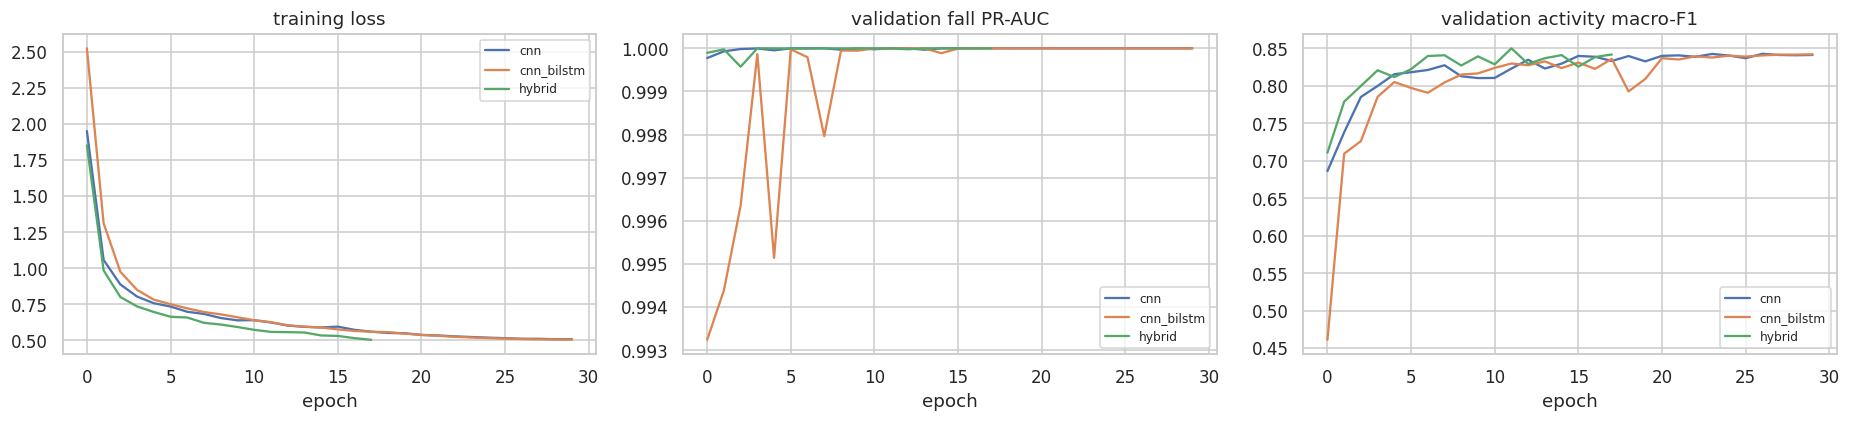

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k, h in HIST.items():
    ax[0].plot(h.epoch, h.loss, label=k); ax[1].plot(h.epoch, h.val_fall_ap, label=k); ax[2].plot(h.epoch, h.val_act_f1, label=k)
for a, t in zip(ax, ['training loss', 'validation fall PR-AUC', 'validation activity macro-F1']):
    a.set_title(t); a.set_xlabel('epoch'); a.legend(fontsize=8)
plt.tight_layout(); save_fig('40_deep_learning_curves'); plt.show()

## 5 · Same streaming test as notebook 3

In [8]:
class Streamer:
    def __init__(self, split):
        sub = wm[wm.split == split].sort_values(['trial_id', 'start'])
        self.rows_global = wm.index.get_indexer(sub.index)
        local = {wid: i for i, wid in enumerate(sub.index)}
        self.trials = []
        for tid, g in sub.groupby('trial_id', sort=False):
            r = meta.loc[tid]
            self.trials.append(dict(tid=tid, rows=np.array([local[w] for w in g.index]), t_end=(g.start.values + W) / FS,
                                    impact=r.peak_idx / FS if r.type == 'Fall' else None, type=r.type, code=r.code,
                                    age=r.age_group, hours=r.duration_s / 3600))
    def alarms(self, p, t_end, thr, k, refractory=10.0):
        hit = p >= thr
        if k > 1: hit = np.convolve(hit.astype(int), np.ones(k, int), 'full')[:len(hit)] >= k
        out, last = [], -1e9
        for t in t_end[hit]:
            if t - last >= refractory: out.append(t); last = t
        return out
    def evaluate(self, p, thr, k=1, detail=False):
        caught, delays, fa, hours, n_fall, rows = 0, [], 0, 0.0, 0, []
        for tr in self.trials:
            al = self.alarms(p[tr['rows']], tr['t_end'], thr, k)
            if tr['type'] == 'Fall':
                n_fall += 1
                ok = [a for a in al if tr['impact'] <= a <= tr['impact'] + W / FS + 0.5]
                caught += bool(ok)
                if ok: delays.append(ok[0] - tr['impact'])
                if detail: rows.append(dict(tid=tr['tid'], code=tr['code'], age=tr['age'], type='Fall', detected=bool(ok),
                                            delay=ok[0] - tr['impact'] if ok else np.nan, n_alarms=len(al)))
            else:
                fa += len(al); hours += tr['hours']
                if detail: rows.append(dict(tid=tr['tid'], code=tr['code'], age=tr['age'], type='ADL', detected=False,
                                            delay=np.nan, n_alarms=len(al)))
        res = dict(sensitivity=caught / max(n_fall, 1), fa_per_hour=fa / max(hours, 1e-9), false_alarms=fa, falls=n_fall,
                   adl_hours=hours, median_delay=float(np.median(delays)) if delays else np.nan)
        return (res, pd.DataFrame(rows)) if detail else res

ST = {s: Streamer(s) for s in ['val', 'test']}
FA_TARGET = 1.0
GRID = np.r_[np.linspace(0.05, 0.95, 19), 0.97, 0.98, 0.99]
def tune_threshold(p_val):
    best = None
    for k in (1, 2):
        for thr in GRID:
            r = ST['val'].evaluate(p_val, thr, k)
            key = (r['fa_per_hour'] <= FA_TARGET, r['sensitivity'], -r['fa_per_hour'])
            if best is None or key > best[0]: best = (key, dict(thr=float(thr), k=k, **r))
    return best[1]
fa_upper = lambda n_fa, h: (3.0 / h) if n_fa == 0 else np.nan       # rule of three, 95 %

In [9]:
deep_rows, PROBS = [], {}
for kind, model in MODELS.items():
    pv, _ = predict(model, ST['val'].rows_global); pt, pat = predict(model, ST['test'].rows_global)
    PROBS[kind] = pt
    cfg = tune_threshold(pv); res = ST['test'].evaluate(pt, cfg['thr'], cfg['k'])
    it = IDX['test']; pf, pa = predict(model, it)
    yf, ya = y_fall[it], y_act[it]
    t0 = time.time(); predict(model, it[:1000]); ms = (time.time() - t0) * 1000
    deep_rows.append(dict(model=f'Deep · {kind}', thr=cfg['thr'], k=cfg['k'], val_sens=cfg['sensitivity'], val_fa_h=cfg['fa_per_hour'],
                          test_sens=res['sensitivity'], test_fa_h=res['fa_per_hour'], fa_upper95=fa_upper(res['false_alarms'], res['adl_hours']),
                          test_delay_s=res['median_delay'],
                          win_prauc=average_precision_score(yf[yf >= 0], pf[yf >= 0]),
                          act_test_f1=f1_score(ya[ya >= 0], pa[ya >= 0].argmax(1), average='macro'),
                          act_test_bacc=balanced_accuracy_score(ya[ya >= 0], pa[ya >= 0].argmax(1)),
                          ms_per_1000_windows=ms, params_k=sum(p.numel() for p in model.parameters()) / 1e3))
    print(f"{kind:10s} test: caught {res['sensitivity']:.3f} | {res['fa_per_hour']:.2f} FA/h | activity F1 {deep_rows[-1]['act_test_f1']:.3f}")
deep = pd.DataFrame(deep_rows)

classic = pd.read_csv(f"{D['artifacts']}/model_arena.csv")
classic['model'] = 'Classic · ' + classic.model
base = pd.read_csv(f"{D['artifacts']}/baselines.csv"); base = base[base.split == 'test'].rename(
    columns={'sensitivity': 'test_sens', 'fa_per_hour': 'test_fa_h'})
ALL = pd.concat([deep, classic], ignore_index=True)
ALL[['model', 'test_sens', 'test_fa_h', 'win_prauc', 'act_test_f1', 'ms_per_1000_windows']].sort_values(
    'act_test_f1', ascending=False).round(4)

cnn        test: caught 0.976 | 0.79 FA/h | activity F1 0.867
cnn_bilstm test: caught 0.976 | 0.00 FA/h | activity F1 0.866
hybrid     test: caught 0.976 | 0.26 FA/h | activity F1 0.870


,model,test_sens,test_fa_h,win_prauc,act_test_f1,ms_per_1000_windows
6,Classic · LightGBM,0.9644,0.0000,0.9953,0.8876,58.0604
9,Classic · XGBoost,0.9644,0.0000,0.9930,0.8846,21.1620
2,Deep · hybrid,0.9756,0.2622,0.9912,0.8702,1195.7009
0,Deep · cnn,0.9756,0.7866,0.9968,0.8667,1197.3798
1,Deep · cnn_bilstm,0.9756,0.0000,0.9923,0.8663,1591.8965
3,Classic · MLP,0.9622,0.0000,0.9970,0.8569,15.4343
10,Classic · RandomForest,0.9289,0.0000,0.9938,0.8545,126.3955
5,Classic · ExtraTrees,0.9467,0.0000,0.9962,0.8519,130.5056
7,Classic · SVM-RBF,0.9889,0.5244,0.9967,0.8354,54.2092
4,Classic · LogReg,0.9600,0.2622,0.9957,0.8161,23.2859


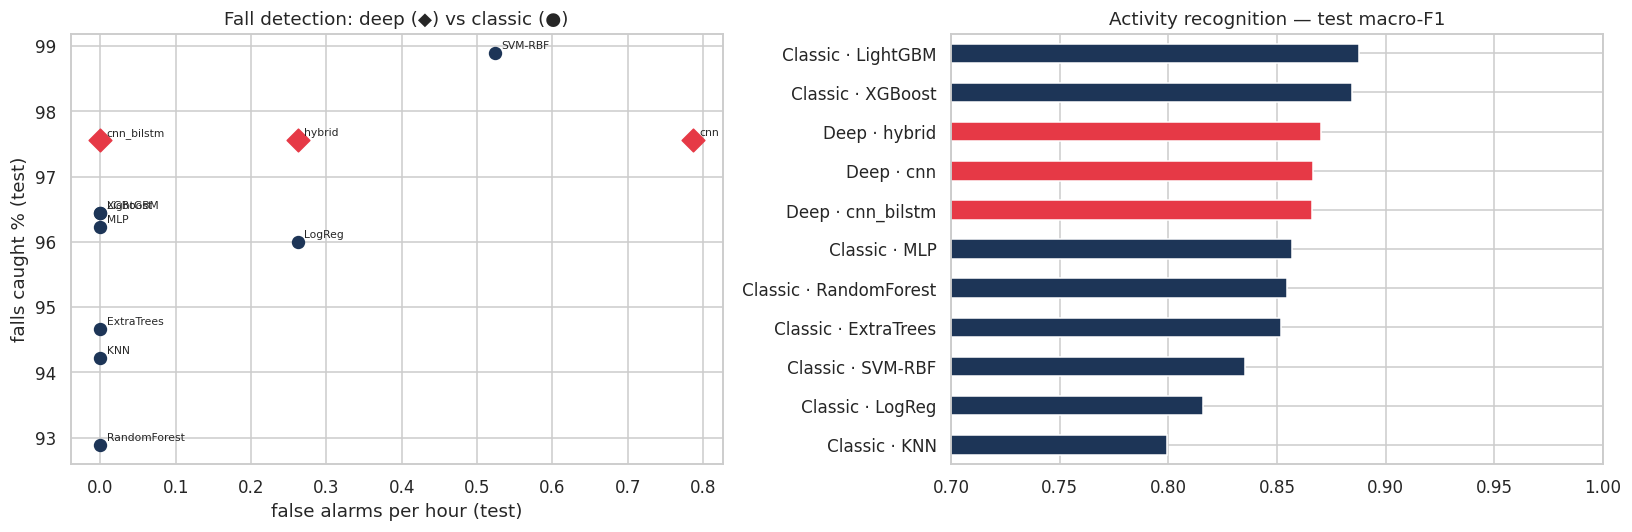

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for _, r in ALL.iterrows():
    deep_ = r.model.startswith('Deep')
    ax[0].scatter(r.test_fa_h, r.test_sens * 100, s=110 if deep_ else 60, color='#e63946' if deep_ else '#1d3557', marker='D' if deep_ else 'o')
    ax[0].annotate(r.model.split(' · ')[1], (r.test_fa_h, r.test_sens * 100), fontsize=7, xytext=(4, 3), textcoords='offset points')
ax[0].set_xlabel('false alarms per hour (test)'); ax[0].set_ylabel('falls caught % (test)'); ax[0].set_title('Fall detection: deep (◆) vs classic (●)')
s = ALL.set_index('model').act_test_f1.sort_values()
s.plot.barh(ax=ax[1], color=['#e63946' if m.startswith('Deep') else '#1d3557' for m in s.index])
ax[1].set_xlim(0.7, 1); ax[1].set_title('Activity recognition — test macro-F1'); ax[1].set_ylabel('')
plt.tight_layout(); save_fig('41_deep_vs_classic'); plt.show()

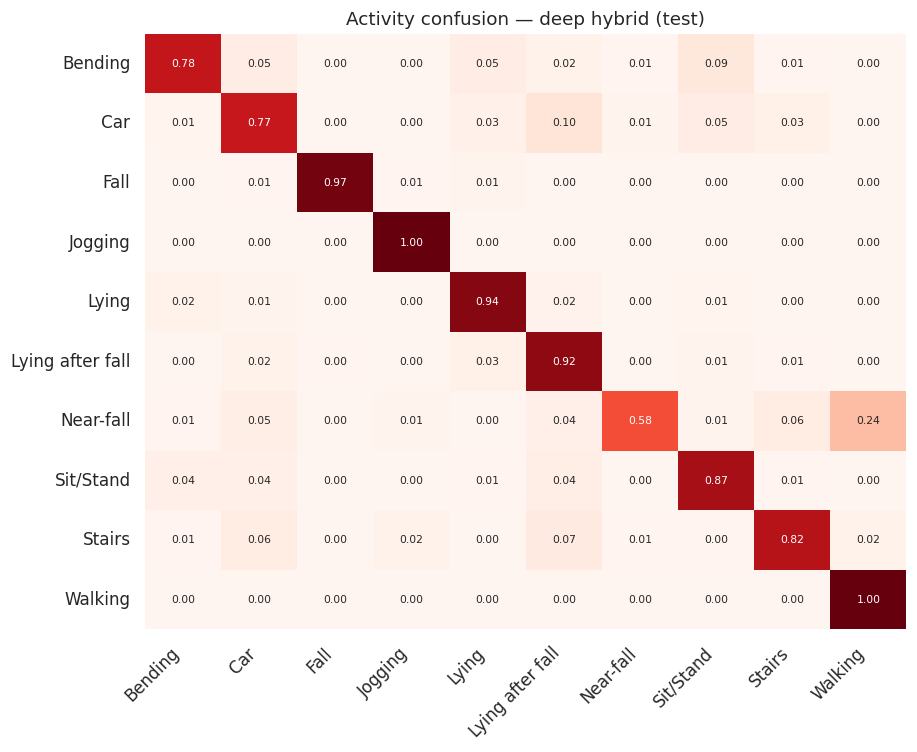

best deep model (by validation): hybrid
                  precision    recall  f1-score   support

         Bending      0.834     0.777     0.804      1898
             Car      0.734     0.766     0.750      2475
            Fall      0.984     0.971     0.977      1800
         Jogging      0.973     0.997     0.985      3702
           Lying      0.856     0.936     0.894      2470
Lying after fall      0.851     0.919     0.884      5203
       Near-fall      0.880     0.578     0.698      1140
       Sit/Stand      0.910     0.866     0.887      4750
          Stairs      0.927     0.816     0.868      3554
         Walking      0.915     0.998     0.955      3900

        accuracy                          0.889     30892
       macro avg      0.886     0.862     0.870     30892
    weighted avg      0.890     0.889     0.887     30892



In [11]:
best_kind = max(MODELS, key=lambda k: (HIST[k].score.max()))            # choose on VALIDATION, not test
model = MODELS[best_kind]
it = IDX['test']; _, pa = predict(model, it); ya = y_act[it]; m = ya >= 0
cm = confusion_matrix(ya[m], pa[m].argmax(1), normalize='true')
plt.figure(figsize=(8.5, 7))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Reds', xticklabels=ACT_CLASSES, yticklabels=ACT_CLASSES, cbar=False, annot_kws={'size': 7})
plt.title(f'Activity confusion — deep {best_kind} (test)'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); save_fig('42_deep_confusion'); plt.show()
print('best deep model (by validation):', best_kind)
print(classification_report(ya[m], pa[m].argmax(1), target_names=ACT_CLASSES, digits=3))

## 6 · Save

In [12]:
deep.to_csv(f"{D['artifacts']}/deep_arena.csv", index=False)
ALL.to_csv(f"{D['artifacts']}/all_models_arena.csv", index=False)
for k, h in HIST.items(): h.to_csv(f"{D['artifacts']}/deep_history_{k}.csv", index=False)
cfgs = {}
for kind, model in MODELS.items():
    pv, _ = predict(model, ST['val'].rows_global); c = tune_threshold(pv)
    cfgs[kind] = dict(thr=c['thr'], k=c['k'])
    m_cpu = MultiTask(kind); m_cpu.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()}); m_cpu.eval()
    ex = (torch.zeros(1, len(CH), W), torch.zeros(1, len(PHONE)))
    torch.jit.trace(m_cpu, ex).save(f'{DEEP}/{kind}_cpu.pt')          # runs in the app without this notebook's code
json.dump({'best_by_validation': best_kind, 'thresholds': cfgs, 'channels': CH, 'window': W, 'fs': FS},
          open(f'{DEEP}/deep_config.json', 'w'), indent=2)
pd.DataFrame({'row': ST['test'].rows_global, **{f'p_{k}': v for k, v in PROBS.items()}}).to_parquet(
    f"{D['data']}/test_stream_probs_deep.parquet", index=False)
print(sorted(os.listdir(DEEP)))

['cnn_best.pt', 'cnn_bilstm_best.pt', 'cnn_bilstm_checkpoint.pt', 'cnn_bilstm_cpu.pt', 'cnn_checkpoint.pt', 'cnn_cpu.pt', 'deep_config.json', 'hybrid_best.pt', 'hybrid_checkpoint.pt', 'hybrid_cpu.pt', 'normalisation.json']
